In [13]:
import numpy as np
import pandas as pd
import json
import os
import cv2
import matplotlib.pyplot as plt
from skimage.transform import resize
from tqdm import tqdm
#new functions
# ------------------------------------------------------------
# Helper: generate random masks (from RISE pipeline)
# ------------------------------------------------------------
def generate_masks(N, s, p1, input_size):
    cell_size = np.ceil(np.array(input_size) / s)
    up_size = (s + 1) * cell_size

    grid = np.random.rand(N, s, s) < p1
    grid = grid.astype('float32')

    masks = np.empty((N, *input_size))

    for i in tqdm(range(N), desc='Generating masks'):
        # Random shifts
        x = np.random.randint(0, cell_size[0])
        y = np.random.randint(0, cell_size[1])
        # Linear upsampling and cropping
        masks[i, :, :] = resize(grid[i], up_size, order=1, mode='reflect',
                                anti_aliasing=False)[x:x + input_size[0], y:y + input_size[1]]
    masks = masks.reshape(-1, *input_size, 1)
    return masks
# Min-max normalize saliency map to [0,1] range
def normalize_heatmap(saliency):
   
    s_min, s_max = np.min(saliency), np.max(saliency)
    if s_max - s_min < 1e-8:  # avoid divide-by-zero
        return np.zeros_like(saliency)
    return (saliency - s_min) / (s_max - s_min)


def save_saliency_results(output_dir, image_name, saliency_maps, feature_confidences):
    """
    Save saliency maps and mean feature confidences to disk.
    - saliency_maps: dict of {feature: 2D numpy array}
    - feature_confidences: dict of {feature: float}
    """

    os.makedirs(output_dir, exist_ok=True)

    # Save per-feature saliency maps (as a compressed numpy archive)
    npz_path = os.path.join(output_dir, f"{image_name}_saliency_maps.npz")
    np.savez_compressed(npz_path, **saliency_maps)

    # Save summary table as CSV
    csv_path = os.path.join(output_dir, f"{image_name}_feature_confidences.csv")
    df = pd.DataFrame(list(feature_confidences.items()), columns=["feature", "mean_confidence"])
    df.to_csv(csv_path, index=False)

    # store metadata in a small JSON file
    meta = {
        "image_name": image_name,
        "num_features": len(feature_confidences),
        "map_shape": {f: sal.shape for f, sal in saliency_maps.items()},
    }
    json_path = os.path.join(output_dir, f"{image_name}_metadata.json")
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)

    print(f"\nSaved results to:\n{npz_path}\n{csv_path}\n{json_path}\n")

# ------------------------------------------------------------
# RISE Wrapper
# ------------------------------------------------------------
def rise_explain(image_url, model_name, demo_features,
                 N, s, p1, input_size=(224, 224)):

    # load image
    resp = requests.get(image_url, timeout=30)
    img = cv2.imdecode(np.frombuffer(resp.content, np.uint8), cv2.IMREAD_COLOR)
    img = cv2.resize(img, input_size)

    # generate masks
    masks = generate_masks(N, s, p1, input_size)

    # run unmasked inference
    tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
    os.close(tmp_fd)
    cv2.imwrite(tmp_path, img)
    _, _, baseline_demo = infer_image_demographics_with_retry(
        tmp_path, model_name, demo_features, prefix="Image_Demo"
    )
    os.remove(tmp_path)
    
    # extract baseline categories
    feature_titles = [re.sub(r"\W+", "_", d["title"]) for d in demo_features]
    baseline_preds = {
        ft: baseline_demo.get(f"Image_Demo_{ft}_Symbol", None)
        for ft in feature_titles
    }

    # Initialize saliency maps
    saliency_sums = {ft: np.zeros(input_size, dtype=np.float32) for ft in feature_titles}

    for i in tqdm(range(N), desc="Generating binary saliency"):
        # apply mask
        masked_img = (img * masks[i]).astype(np.uint8)

        # save temp file
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, masked_img)

        # infer demographics with Azure pipeline
        _, _, parsed_demo = infer_image_demographics_with_retry(
            tmp_path, model_name, demo_features, prefix="Image_Demo"
        )

        os.remove(tmp_path)

        for ft in feature_titles:
            base_pred = baseline_preds.get(ft)
            masked_pred = parsed_demo.get(f"Image_Demo_{ft}_Symbol", None)
            if base_pred is not None:
                base_pred = str(base_pred).strip().lower()
            if masked_pred is not None:
                masked_pred = str(masked_pred).strip().lower()
            if base_pred is None or masked_pred is None:
                print(f"Feature {ft} not found in parsed_demo/based_demo")
                continue
            score = 1.0 if masked_pred == base_pred else 0.0
            saliency_sums[ft] += masks[i, :, :, 0] * score
    # Normalize saliency maps
    saliency_maps = {}
    feature_confidences = {}

    for ft, sal in saliency_sums.items():
        # normalize by number of masks and probability
        sal /= (N * p1)

        # compute "confidence" = average saliency score across all pixels
        raw_conf = np.mean(sal)
        feature_confidences[ft] = raw_conf

        # normalize to [0,1] for visualization
        saliency_maps[ft] = normalize_heatmap(sal)

    # Print out confidence per feature
    print("\n=== Raw Feature Confidence Scores (mean saliency) ===")
    for ft, conf in feature_confidences.items():
        print(f"{ft:<40}: {conf:.4f}")
    # Save outputs for analysis
    image_name = os.path.splitext(os.path.basename(image_url))[0]  # or "demo_image"
    output_dir = "./saliency_outputs"

    save_saliency_results(output_dir, image_name, saliency_maps, feature_confidences)

    return img, saliency_maps, baseline_symbols, feature_confidences
# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------
def show_saliency(img, saliency, title="Saliency Map"):
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.imshow(saliency.squeeze(), cmap='jet', alpha=0.5)
    plt.title(title)
    plt.axis("off")
    plt.show()


In [2]:
import os
import requests
import json
import time
import re
import random
import unicodedata
import pandas as pd
import tempfile
import base64
import mimetypes
def normalize_text(text):
    # Normalize unicode characters, remove markdown formatting, lowercase, and strip dashes
    if not text:
        return text
    
    text = str(text)
    text = text.replace('*', '').replace('<<', '').replace('>>', '')
    text = re.sub(r'[-\u2010-\u2015\u2212\uFE58\uFE63\uFF0D]', '', text)
    normalized = unicodedata.normalize('NFKD', text)
    ascii_text = normalized.encode('ASCII', 'ignore').decode('ASCII')

    # Clean up whitespace + lowercase
    return ' '.join(ascii_text.split()).lower()

def send_prompt(
    system=None,
    prompt=None,
    image_url=None,             # if set, we download to a temp file and inline it
    image_path=None,            # local file path (sent as data URL)
    image_detail="auto",        
    seed=None,
    azure_api_key=os.getenv("AZURE_API_KEY"),
    azure_chat_url=None,        # built if not provided
    azure_model_name=os.getenv("AZURE_MODEL_NAME"),
    max_completion_tokens=1024,
    temperature=float(os.getenv("TEMPERATURE", "1.0")),
    top_p=float(os.getenv("TOP_P", "1.0")),
    frequency_penalty=float(os.getenv("FREQUENCY_PENALTY", "0.0")),
    presence_penalty=float(os.getenv("PRESENCE_PENALTY", "0.0")),
    max_time=int(os.getenv("MAX_TIME", "30"))
):

    # --- default azure_chat_url if not supplied ---
    if azure_chat_url is None:
        azure_endpoint_base = "https://aipolling.services.ai.azure.com/models"
        azure_api_version  = "2024-05-01-preview"
        azure_chat_url = f"{azure_endpoint_base}/chat/completions?api-version={azure_api_version}"

    # --- helpers ---
    def guess_mime_from_ext(path):
        """Guess MIME type from file extension, fallback to image/jpeg."""
        mime, _ = mimetypes.guess_type(path)
        return mime if mime else "image/jpeg"

    def image_to_data_url(path, mime=None):
        """Read file, encode as base64, return as data URL."""
        if not os.path.exists(path):
            raise FileNotFoundError(f"image_path not found: {path}")
        if mime is None:
            mime = guess_mime_from_ext(path)
        with open(path, "rb") as f:
            encoded = base64.b64encode(f.read()).decode("utf-8")
        return f"data:{mime};base64,{encoded}"

    tmp_path = None
    # If image_url is provided, download it
    if image_url:
        ext = os.path.splitext(image_url)[1].lower()
        suffix = ext if ext else ".bin"
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=suffix)
        os.close(tmp_fd)  # we'll reopen with write
        resp_img = requests.get(image_url, timeout=max_time)
        if resp_img.status_code >= 400:
            raise RuntimeError(f"Failed to download image_url (HTTP {resp_img.status_code}): {image_url}")
        with open(tmp_path, "wb") as f:
            f.write(resp_img.content)
        image_path = tmp_path

    # --- build messages ---
    messages_list = []
    if system:
        messages_list.append({"role": "system", "content": system})

    user_content = [{"type": "text", "text": prompt}]

    if image_path:
        mime = guess_mime_from_ext(image_path)
        data_url = image_to_data_url(image_path, mime)
        user_content.append({
            "type": "image_url",
            "image_url": {"url": data_url, "detail": image_detail}
        })

    messages_list.append({"role": "user", "content": user_content})

    # --- body payload ---
    body = {
        "model": azure_model_name,
        "messages": messages_list,
        "temperature": float(temperature),
        "top_p": float(top_p),
        "frequency_penalty": float(frequency_penalty),
        "presence_penalty": float(presence_penalty),
        "max_completion_tokens": int(max_completion_tokens),
        "max_tokens": int(max_completion_tokens),  # compat
        "seed": int(seed) if seed is not None else None
    }

    # --- request ---
    headers = {
        "Content-Type": "application/json",
        "Accept": "application/json",
        "api-key": azure_api_key
    }

    resp = requests.post(
        azure_chat_url,
        headers=headers,
        json=body,
        timeout=max_time
    )

    raw_content = resp.text
    if resp.status_code != 200:
        raise RuntimeError(f"API request failed with status {resp.status_code}, body: {raw_content}")

    result = resp.json()

    # --- cleanup tmp file if used ---
    if tmp_path and os.path.exists(tmp_path):
        try:
            os.remove(tmp_path)
        except Exception:
            pass

    return result

# ------------------------------------------------------------
# 2. Load demographic categories from JSON
# ------------------------------------------------------------
with open("../generated_data/image_belief_features.json", "r", encoding="utf-8") as f:
    feature_data = json.load(f)

demo_features = feature_data["demo"]

# Normalize titles for the matching
for demo in demo_features:
    demo["title"] = normalize_text(demo["title"])

# ------------------------------------------------------------
# 3. Image prompt for demographic features
# ------------------------------------------------------------
image_prompt_template = """
I will show you a social media user's profile image.

Based SOLELY on this profile image, I will show you a number of demographic categories to which this user may belong to.
The categories are preceded by a title (e.g. "AGE:" or "SEX:" etc.) and a symbol (e.g. "A1", "A2" or "E1" etc.).
Please select, for each title, the most likely category to which this user belongs to BASED SOLELY ON THE VISUAL CONTENT OF THE PROFILE IMAGE.

In your answer present, for each title, the selected symbol.
Write out in full the category associated with the selected symbol.
The chosen symbol / category must be the most likely to accurately represent this user.
You must only select one symbol / category per title.
A title, symbol and category cannot appear more than once in your answer.

For each selected symbol / category, please note the level of Speculation involved in this selection.
Present the Speculation level for each selection on a scale from 0 (not speculative at all, clear visual evidence in the profile image) to 100 (fully speculative, no visual information related to this title in the profile image).
Speculation levels should be a direct measure of the amount of useful visual information available in the profile image.
Speculation levels pertain only to the visual information available in the profile image and should not be affected by additional information available to you from any other source.


To ensure consistency, use the following guidelines to determine speculation levels:

0-20 (Low speculation): The profile image provides clear and direct visual information relevant to the title (e.g., explicit visual evidence of age, gender presentation, etc.)
21-40 (Moderate-low speculation): The profile image provides indirect but strong visual indicators relevant to the title.
41-60 (Moderate speculation): The profile image provides some visual hints or partial information relevant to the title.
61-80 (Moderate-high speculation): The profile image provides limited and weak visual indicators relevant to the title.
81-100 (High speculation): The profile image provides no or almost no visual information relevant to the title.

For each selected category, please explain at length what visual features of the profile image contributed to your choice and your speculation level.

Preserve a strictly structured answer to ease parsing of the text.
Format your output as follows (this is just an example):

title: AGE
explanation: ...
symbol: A1)
category: 18-25
speculation: 90

For every title, you must include exactly these 5 fields: title, explanation, symbol, category, speculation. Do not omit any of them.
Please keep the EXACT WORDING for the titles!
YOU MUST GIVE AN ANSWER FOR EVERY TITLE!
"""

# ------------------------------------------------------------
# 4. Build dynamic image demographic prompt
# ------------------------------------------------------------
def build_image_demo_prompt(demo_features):
    
    # randomly shuffle the demographics to prevent position bias
    shuffled_demo = demo_features[:]
    random.shuffle(shuffled_demo)

    categories_text = "\n".join(
        [
            f"- **{demo['title']}:** \n    Choose one: [\n    " +
            ", \n    ".join([f"{key}) {val}" for key, val in demo["options"].items()]) +
            "]"
            for demo in shuffled_demo
        ]
    )

    return image_prompt_template + "\n\nBelow is the list of demographic categories to which this user may belong to:\n" + categories_text

# ----------------------------
# 5. Result Parsing Function
# ----------------------------

def parse_demo_response(response, demo_features, prefix="Image_Demo"):
    categories = {}
    explanations = {}
    speculations = {}
    symbols = {}

    for demo in demo_features:
        safe_key = re.sub(r"\W+", "_", demo["title"])
        if prefix:
            safe_key = f"{prefix}_{safe_key}"
        categories[f"{safe_key}_Category"] = None
        explanations[f"{safe_key}_Explanation"] = None
        symbols[f"{safe_key}_Symbol"] = None
        speculations[f"{safe_key}_Speculation"] = None

    demo_sections = re.split(r"(?=title:\s*)", str(response), flags=re.IGNORECASE)
    demo_sections = [section.strip() for section in demo_sections if section.strip() and not section.lower().startswith('below')]
    print(f"[DEBUG] Found {len(demo_sections)} sections to parse") 
    
    # Pattern for individual demographic
    pattern = (
        r"title:?\s*(.*?)\s*[\r\n]"
        r"explanation:?\s*(.*?)\s*[\r\n]"
        r"symbol:?\s*(.*?)\s*[\r\n]"
        r"category:?\s*(.*?)\s*[\r\n]"
        r"speculation:?\s*(\d+)\s*"
    )
    
    for i, section in enumerate(demo_sections):
        
        match = re.search(pattern, section, re.DOTALL | re.IGNORECASE)
        
        if match:
            title = normalize_text(match.group(1))
            explanation = normalize_text(match.group(2))
            symbol = normalize_text(match.group(3))
            category = normalize_text(match.group(4))
            speculation = normalize_text(match.group(5))
            
            matched_demo = None
            for d in demo_features:
                if d["title"] in title or title in d["title"]:
                    matched_demo = d
                    break
            if matched_demo:
                safe_key = re.sub(r"\W+", "_", matched_demo["title"])
                if prefix:
                    safe_key = f"{prefix}_{safe_key}"
                categories[f"{safe_key}_Category"] = category.strip()
                explanations[f"{safe_key}_Explanation"] = explanation.strip()
                symbols[f"{safe_key}_Symbol"] = symbol.strip()
                speculations[f"{safe_key}_Speculation"] = int(speculation.strip())

    return {**categories, **explanations, **speculations, **symbols}

# ------------------------------------------------------------
# 6. Build the request body for image inference using send_prompt
# ------------------------------------------------------------
def infer_image_demographics(image_url = None, image_path = None, model_name = None, demo_features = None):
    prompt = build_image_demo_prompt(demo_features)
    
    system_message = "You are a helpful assistant."

    try:
        result = send_prompt(
            system=system_message,
            prompt=prompt,
            image_url=image_url,
            image_path = image_path,
            azure_model_name=model_name,
            max_completion_tokens=16384,
            max_time=60
        )
        
        reply = result["choices"][0]["message"]["content"]
        return reply
        
    except Exception as e:
        print(f"Error in send_prompt: {e}")
        raise

# ------------------------------------------------------------
# 7. Secondary GPT cleanup function
# ------------------------------------------------------------
image_cleanup_prompt_template = """
You will be shown a long-form response to a question asking to assign a series of demographic categories to a user based solely on their profile image.
Your task is to extract and reformat the category assessments into a strict format.

CRITICAL FORMATTING RULES:
- Each demographic must be formatted EXACTLY as follows:
title: <FULL TITLE TEXT>
explanation: <FULL EXPLANATION TEXT>
symbol: <SYMBOL CODE>
category: <FULL CATEGORY TEXT>
speculation: <NUMERIC VALUE ONLY>

- Each field must be on its own separate line
- Preserve ALL original content from explanations, categories, and titles - do not summarize or shorten
- For speculation, use ONLY the numeric value (e.g., "50" not "fifty" or "50%")
- Remove any asterisks, markdown, or extra formatting from the original
- Ensure there is exactly one blank line between each complete demographic assessment
- If any field is missing, include the field name with nothing after it (e.g., "explanation:")

CHARACTER AND ENCODING RULES:
- Use only standard ASCII hyphens (-) for all dashes and hyphens in titles and categories
- Replace any special dashes (‑, –, —) with regular hyphens (-)
- Ensure all text uses standard ASCII characters only
- Remove any non-ASCII characters or convert them to their closest ASCII equivalent
- Use regular parentheses () not special parentheses

EXAMPLES OF CORRECT FORMATTING:

Example 1:
title: AGE
explanation: The profile image shows a person with visible wrinkles and gray hair...
symbol: A1)
category: 18-25
speculation: 50

Example 2:
title: SEX
explanation: The profile image presents masculine facial features and short haircut...
symbol: E1)
category: Male
speculation: 75

COMMON MISTAKES TO AVOID:
- WRONG: speculation: fifty (50)
- CORRECT: speculation: 50

- WRONG: symbol: E1) (with extra spaces)
- CORRECT: symbol: E1)

- WRONG: Using markdown like **title:**
- CORRECT: title:

- WRONG: Combining multiple fields on one line
- CORRECT: Each field on its own line

Now, clean and reformat the following response to match this exact structure. Preserve all original meaning but enforce the strict formatting and character rules:

{raw_output}
"""

def clean_image_output(raw_output, model_name):
    system_message = "You are a helpful assistant."
    
    try:
        result = send_prompt(
            system=system_message,
            prompt=image_cleanup_prompt_template.format(raw_output=raw_output),
            azure_model_name=model_name,
            max_completion_tokens=16384,
            max_time=60
        )
        
        reply = result["choices"][0]["message"]["content"]
        return reply
        
    except Exception as e:
        print(f"Error in cleanup send_prompt: {e}")
        raise

# ------------------------------------------------------------
# 8. GPT call with retry logic for image demographics
# ------------------------------------------------------------
def infer_image_demographics_with_retry(image_source, model_name, demo_features, prefix="Image_Demo", max_retries=5):
    parsed_result = {}
    response_text = None
    cleaned_text = None
    
    for attempt in range(1, max_retries + 1):
        try:
            if str(image_source).startswith("http"):
                response_text = infer_image_demographics(
                    image_url = image_source, 
                    model_name = model_name, 
                    demo_features=demo_features)
            else:
                response_text = infer_image_demographics(
                    image_path = image_source, 
                    model_name = model_name, 
                    demo_features=demo_features)
                
            parsed_result = parse_demo_response(response_text, demo_features, prefix=prefix)

            # if parsed result is incomplete, proceed with secondary cleanup
            if any(value is None for value in parsed_result.values()):
                print(f"[DEBUG] Parsing incomplete for image demographics → attempting cleanup.")
                cleaned_text = clean_image_output(response_text, model_name)
                parsed_result = parse_demo_response(cleaned_text, demo_features, prefix=prefix)

            # if still incomplete, raise exception to retry full GPT
            if any(value is None for value in parsed_result.values()):
                raise ValueError("Parsed result is empty. Retrying...")
            else:
                print(f"Image demographic parsing succeeded")
            return response_text, cleaned_text, parsed_result

        except Exception as e:
            print(f"Attempt {attempt}/{max_retries} failed for image demographics ({model_name}): {e}")
            if attempt < max_retries:
                time.sleep(2 ** attempt * 0.1)  
    
    return response_text, cleaned_text, parsed_result

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sect

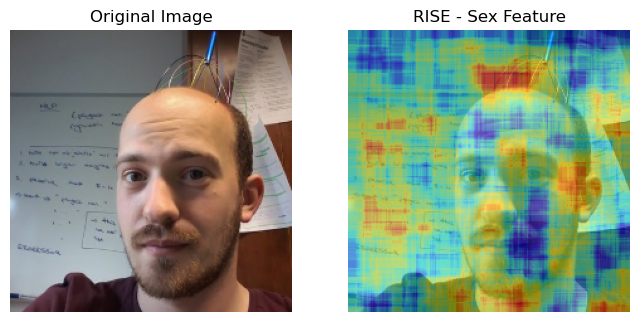

NameError: name 'image_source' is not defined

In [ ]:
img, saliency = rise_explain(
    image_url="https://pbs.twimg.com/profile_images/776047601816829953/suLLGY-y_400x400.jpg",
    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
    demo_features=demo_features,
    feature_title="sex",  
    N=200  
)

show_saliency(img, saliency, title="RISE - Sex Feature")
infer_image_demographics(
                    image_url = image_url, 
                    model_name = model_name, 
                    demo_features=demo_features)

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sect

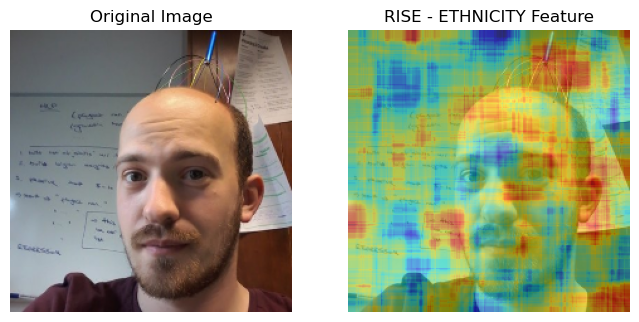

NameError: name 'image_url' is not defined

In [ ]:
img, saliency = rise_explain(
    image_url="https://pbs.twimg.com/profile_images/776047601816829953/suLLGY-y_400x400.jpg",
    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
    demo_features=demo_features,
    feature_title="ethnicity",  
    N=200  
)

show_saliency(img, saliency, title="RISE - ETHNICITY Feature")
# infer_image_demographics(
#                     image_url = image_url, 
#                     model_name = model_name, 
#                     demo_features=demo_features)

Generating masks: 100%|██████████| 200/200 [00:00<00:00, 953.24it/s]


[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sect

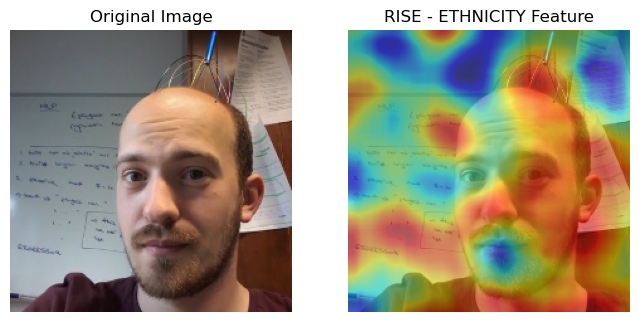

In [ ]:
img, saliency = rise_explain(
    image_url="https://pbs.twimg.com/profile_images/776047601816829953/suLLGY-y_400x400.jpg",
    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
    demo_features=demo_features,
    feature_title="ethnicity",  
    N=200  
)

show_saliency(img, saliency, title="RISE - ETHNICITY Feature")
# infer_image_demographics(
#                     image_url = image_url, 
#                     model_name = model_name, 
#                     demo_features=demo_features)

Generating masks: 100%|██████████| 2000/2000 [00:02<00:00, 788.28it/s]


[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sect

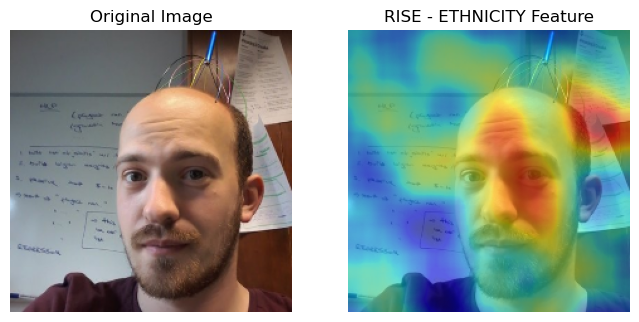

In [ ]:
img, saliency = rise_explain(
    image_url="https://pbs.twimg.com/profile_images/776047601816829953/suLLGY-y_400x400.jpg",
    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
    demo_features=demo_features,
    feature_title="ethnicity",  
    N=2000  
)

show_saliency(img, saliency, title="RISE - ETHNICITY Feature")
# infer_image_demographics(
#                     image_url = image_url, 
#                     model_name = model_name, 
#                     demo_features=demo_features)

Generating masks: 100%|██████████| 200/200 [00:00<00:00, 1035.32it/s]


[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sect

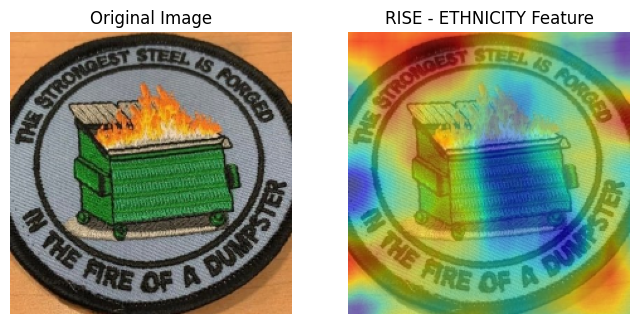

In [3]:
img, saliency = rise_explain(
    image_url="https://pbs.twimg.com/profile_images/1785346593236951040/3WO9o6Jj.jpg",
    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
    demo_features=demo_features,
    feature_title="ethnicity",  
    N=200  
)

show_saliency(img, saliency, title="RISE - ETHNICITY Feature")
# infer_image_demographics(
#                     image_url = image_url, 
#                     model_name = model_name, 
#                     demo_features=demo_features)

Generating masks: 100%|██████████| 200/200 [00:00<00:00, 1054.37it/s]


[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


Generating binary saliency:   0%|          | 1/200 [00:05<19:02,  5.74s/it]

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


Generating binary saliency:   1%|          | 2/200 [00:10<17:49,  5.40s/it]

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


... (392 outputs left out)

Generating binary saliency: 100%|█████████▉| 199/200 [17:45<00:06,  6.05s/it]

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


Generating binary saliency: 100%|██████████| 200/200 [17:50<00:00,  5.35s/it]

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
ethnicity baseline symbol: e1


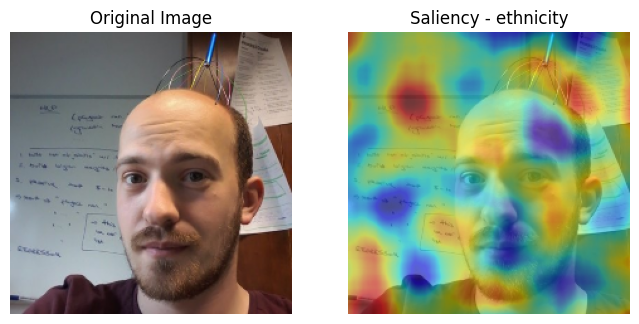

age baseline symbol: a3


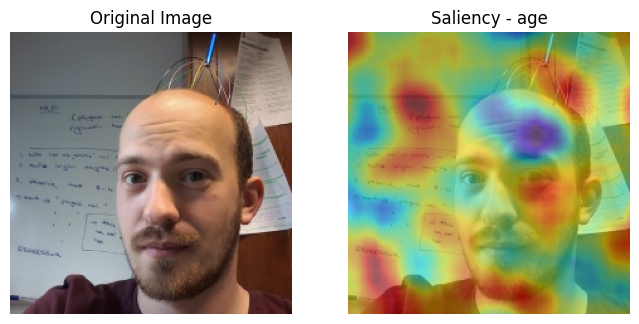

sex baseline symbol: s1


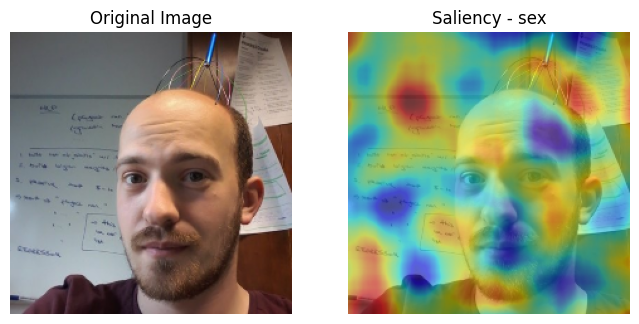

highest_educational_qualification baseline symbol: q2


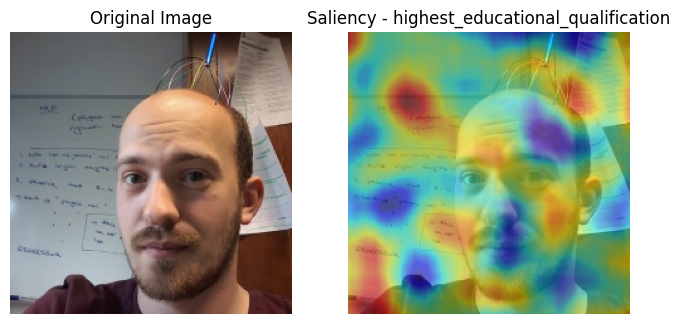

household_income_bracket baseline symbol: h3


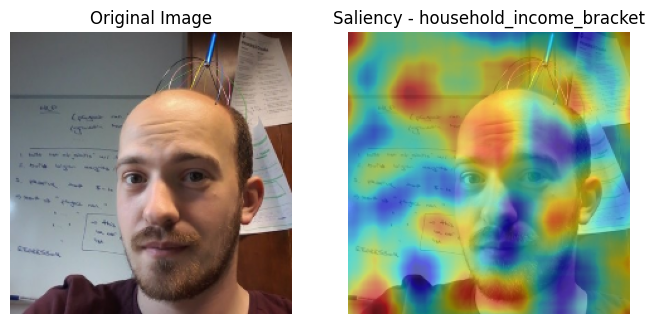

partisan_loyalties baseline symbol: pid4


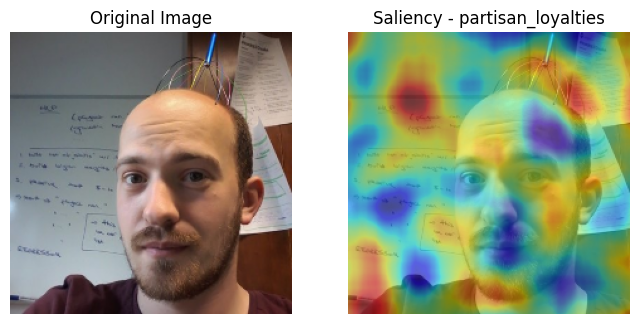

In [ ]:
img, saliency_maps, baseline_symbols = rise_explain(
    image_url="https://pbs.twimg.com/profile_images/776047601816829953/suLLGY-y_400x400.jpg",
    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
    demo_features=demo_features,
    N=200  
    s=8, 
    p1 = 0.5)
)

for feature, saliency in saliency_maps.items():
    print(f"{feature} baseline symbol:", baseline_symbols[feature])
    show_saliency(img, saliency, title=f"Saliency - {feature}")

Generating masks: 100%|██████████| 200/200 [00:00<00:00, 956.44it/s]


[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


Generating binary saliency:   0%|          | 1/200 [00:05<17:47,  5.36s/it]

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


Generating binary saliency:   1%|          | 2/200 [00:11<18:34,  5.63s/it]

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


... (392 outputs left out)

Generating binary saliency: 100%|█████████▉| 199/200 [18:25<00:05,  5.25s/it]

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


Generating binary saliency: 100%|██████████| 200/200 [18:30<00:00,  5.55s/it]

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded

=== Raw Feature Confidence Scores (mean saliency) ===
ethnicity                               : 0.6958
age                                     : 0.5270
sex                                     : 0.6958
highest_educational_qualification       : 0.6797
household_income_bracket                : 0.4930
partisan_loyalties                      : 0.6849

Saved results to:
./saliency_outputs\suLLGY-y_400x400_saliency_maps.npz
./saliency_outputs\suLLGY-y_400x400_feature_confidences.csv
./saliency_outputs\suLLGY-y_400x400_metadata.json

ethnicity baseline symbol: e1


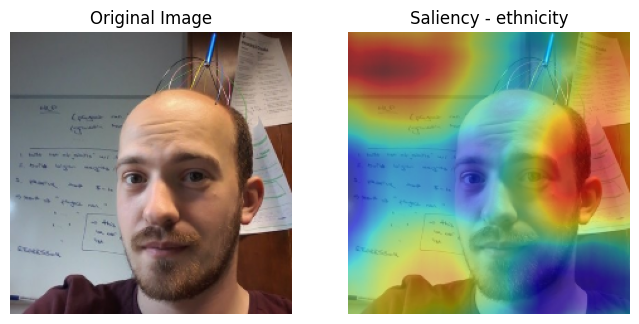

age baseline symbol: a3


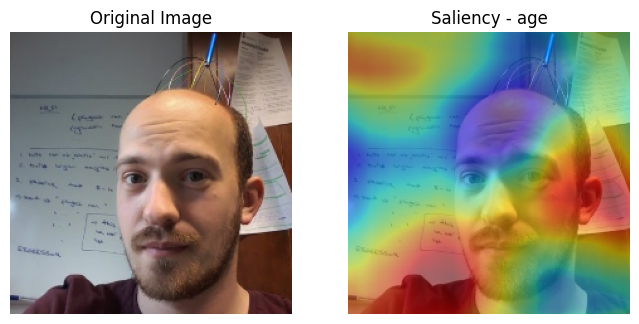

sex baseline symbol: s1


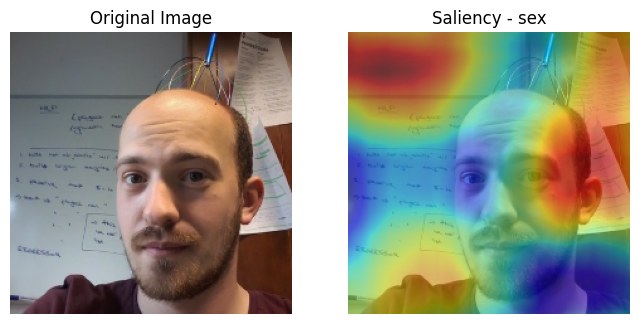

highest_educational_qualification baseline symbol: q2


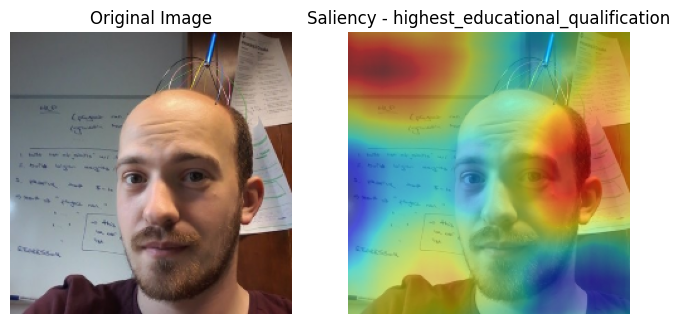

household_income_bracket baseline symbol: h3


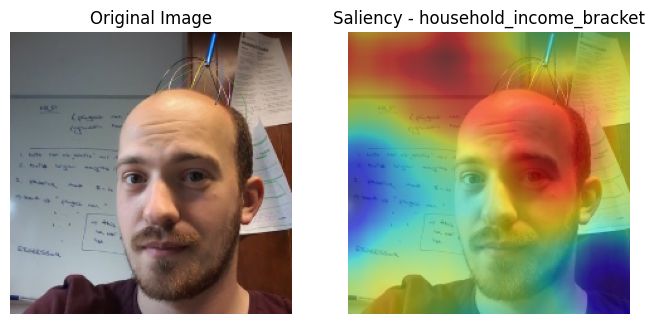

partisan_loyalties baseline symbol: pid4


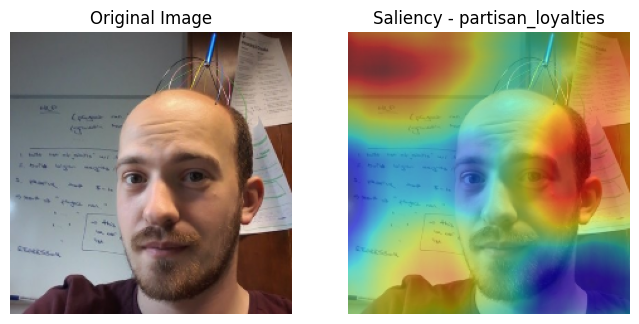

In [14]:
img, saliency_maps, baseline_symbols, feature_confidences = rise_explain(
    image_url="https://pbs.twimg.com/profile_images/776047601816829953/suLLGY-y_400x400.jpg",
    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
    demo_features=demo_features,
    N=200,  
    s=4, 
    p1 = 0.5)

for feature, saliency in saliency_maps.items():
    print(f"{feature} baseline symbol:", baseline_symbols[feature])
    show_saliency(img, saliency, title=f"Saliency - {feature}")

In [16]:
import numpy as np
data = np.load("saliency_outputs/suLLGY-y_400x400_saliency_maps.npz")

for k in data.files:
    print(k, data[k].shape, data[k].min(), data[k].max(), data[k].mean())


ethnicity (224, 224) 0.0 1.0 0.5204101
age (224, 224) 0.0 1.0 0.5282474
sex (224, 224) 0.0 1.0 0.5204101
highest_educational_qualification (224, 224) 0.0 1.0 0.5449902
household_income_bracket (224, 224) 0.0 1.0 0.594665
partisan_loyalties (224, 224) 0.0 1.0 0.5478223


In [17]:
data

NpzFile 'saliency_outputs/suLLGY-y_400x400_saliency_maps.npz' with keys: ethnicity, age, sex, highest_educational_qualification, household_income_bracket...

In [19]:
import pandas as pd
csv = pd.read_csv("saliency_outputs/suLLGY-y_400x400_feature_confidences.csv")
for _, row in csv.iterrows():
    ft = row["feature"]
    mean_csv = row["mean_confidence"]
    mean_npz = data[ft].mean()
    print(ft, mean_csv, mean_npz, abs(mean_csv - mean_npz))


ethnicity 0.69577503 0.5204101 0.17536491
age 0.52698785 0.5282474 0.0012595654
sex 0.69577503 0.5204101 0.17536491
highest_educational_qualification 0.67972237 0.5449902 0.13473219
household_income_bracket 0.4930105 0.594665 0.1016545
partisan_loyalties 0.684934 0.5478223 0.13711172


C:\Users\yuyue\AppData\Local\Temp\ipykernel_5404\4135567793.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([data[k].ravel() for k in data.files], labels=data.files)


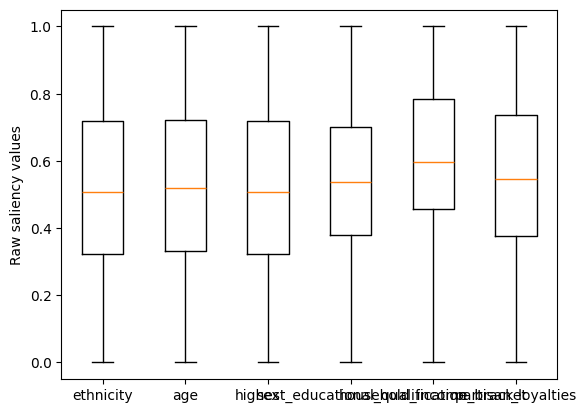

In [20]:
import matplotlib.pyplot as plt
plt.boxplot([data[k].ravel() for k in data.files], labels=data.files)
plt.ylabel("Raw saliency values")
plt.show()


In [25]:
feature = "sex"  
sal = data[feature]

print(f"{feature} saliency shape:", sal.shape)
print("First few raw pixel values (flattened):", sal.ravel()[:20])
print("Min:", sal.min(), "Max:", sal.max(), "Mean:", sal.mean(), "Std:", sal.std())
print(len(sal))

sex saliency shape: (224, 224)
First few raw pixel values (flattened): [0.7965809  0.78979915 0.78365564 0.77614945 0.76897043 0.76243085
 0.75762373 0.75366473 0.7495394  0.7468975  0.74501914 0.7431444
 0.7438068  0.7456763  0.7460635  0.7462984  0.74609816 0.74546313
 0.7452355  0.7443245 ]
Min: 0.0 Max: 1.0 Mean: 0.5204101 Std: 0.23625594
224
